# 08 · Liquid-liquid extraction

When distillation fails - heat-sensitive products, close boiling points, azeotropes, dilute aqueous streams -
a second liquid can pull the solute out. Extraction is distillation's stage-wise cousin with a solvent in
place of heat, and the same ideas: distribution coefficient in place of relative volatility, extraction factor
in place of the absorption factor, and stages stepped on a diagram. This notebook designs immiscible-solvent
extractions with the Kremser equation and partially miscible ones on triangular coordinates.

**What you will learn**
- compare single-stage, cross-current and countercurrent extraction
- use the extraction factor and find minimum solvent
- read triangular diagrams and tie lines
- apply the Hunter-Nash construction

**Before you start:** notebooks 03 and 06  ·  **Time:** about 75 min

In [1]:
try:                      # on Google Colab (or anywhere engsep is missing): install it from GitHub
    import engsep
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engsep"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from engsep import datasets
from engsep import extraction as ex
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## Immiscible solvent: one stage, many stages, countercurrent

In [2]:
K, x_in = 2.5, 0.05                                                 # distribution coefficient (extract/raffinate), feed solute fraction
for S_over_F in (0.5, 1.0, 2.0):
    one = ex.single_stage_immiscible(K, S_over_F, x_in)
    cross = ex.crosscurrent_immiscible(K, S_over_F / 4, x_in, 4)
    counter = ex.countercurrent_immiscible(K, S_over_F, x_in, 4)
    print(f"S/F = {S_over_F}: single stage {one['fraction_extracted']:.3f}; 4 cross-current stages (same total solvent) {cross['fraction_extracted']:.3f}; 4 countercurrent {counter['fraction_extracted']:.3f}")

S/F = 0.5: single stage 0.556; 4 cross-current stages (same total solvent) 0.663; 4 countercurrent 0.878
S/F = 1.0: single stage 0.714; 4 cross-current stages (same total solvent) 0.857; 4 countercurrent 0.984
S/F = 2.0: single stage 0.833; 4 cross-current stages (same total solvent) 0.961; 4 countercurrent 0.999


With the same total solvent, splitting it over four cross-current stages beats one stage, and running the
four countercurrently beats both - the solvent meets the leanest raffinate last, when it is still fresh.
Countercurrent contact is the rule for the same reason as in absorption and distillation: it keeps the
driving force alive along the whole cascade.

## The extraction factor and the number of stages

In [3]:
x_out = 0.001                                                         # 98 % recovery
S_min = ex.minimum_solvent_immiscible(K, x_in, x_out)
print(f"minimum solvent S/F = {S_min:.3f} (E = {ex.extraction_factor(K, S_min):.3f})")
for f in (1.2, 1.5, 2.0, 3.0):
    E = ex.extraction_factor(K, f * S_min)
    print(f"S/F = {f} S_min: E = {E:.2f}, stages = {ex.countercurrent_stages_immiscible(K, f * S_min, x_in, x_out):.2f}")

minimum solvent S/F = 0.392 (E = 0.980)
S/F = 1.2 S_min: E = 1.18, stages = 13.08
S/F = 1.5 S_min: E = 1.47, stages = 7.30
S/F = 2.0 S_min: E = 1.96, stages = 4.78
S/F = 3.0 S_min: E = 2.94, stages = 3.25


The extraction factor $E = KS/F$ plays the role of the absorption factor, and the stage count follows the
Kremser equation: infinite at the minimum solvent, falling steeply as $E$ passes 1.3-2. Solvent costs
recovery (usually by distillation), so the design point is again a compromise, typically $E$ between 1.3
and 2.

## Partially miscible systems: the triangular diagram

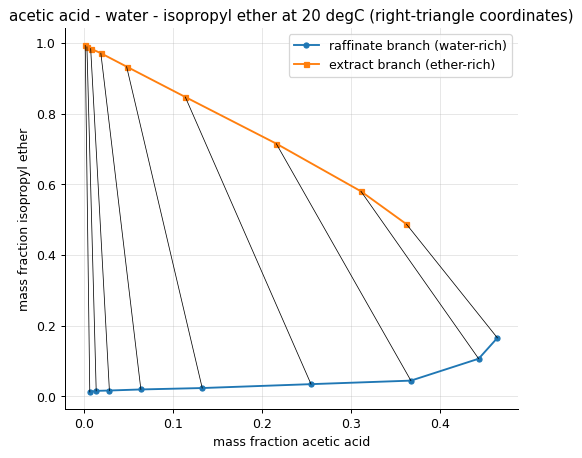

distribution coefficient K = yA/xA along the tie lines: [0.26 0.26 0.27 0.3  0.36 0.45 0.59 0.7  0.78]


In [4]:
d = pd.read_csv(datasets.path("ternary_acetic_water_ether.csv"), comment="#")
tern = ex.Ternary(np.c_[d.xA_raffinate, d.xS_raffinate], np.c_[d.yA_extract, d.yS_extract], np.c_[d.xA_raffinate, d.yA_extract])
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.plot(d.xA_raffinate, d.xS_raffinate, "o-", ms=4, label="raffinate branch (water-rich)"); ax.plot(d.yA_extract, d.yS_extract, "s-", ms=4, label="extract branch (ether-rich)")
for r, e in zip(np.c_[d.xA_raffinate, d.xS_raffinate], np.c_[d.yA_extract, d.yS_extract]):
    ax.plot([r[0], e[0]], [r[1], e[1]], "k-", lw=0.6)
ax.set(xlabel="mass fraction acetic acid", ylabel="mass fraction isopropyl ether", title="acetic acid - water - isopropyl ether at 20 degC (right-triangle coordinates)"); ax.legend(); plt.show()
print("distribution coefficient K = yA/xA along the tie lines:", np.round((d.yA_extract / d.xA_raffinate).to_numpy(), 2))

Water and isopropyl ether are almost immiscible, and acetic acid distributes between them - poorly, with a
distribution coefficient of 0.3-0.8 that changes along the tie lines: ether is a weak solvent for acetic acid.
On triangular (here right-triangle) coordinates the two branches of the binodal curve and the tie lines
carry all the equilibrium information; the lever rule does the balances.

## The Hunter-Nash construction

In [5]:
F, xF = 100.0, (0.30, 0.0)                                            # kg/h of 30 % acetic acid in water
xS = (0.0, 1.0)                                                       # pure ether
for S in (150.0, 250.0, 400.0, 600.0):
    try:
        hn = ex.hunter_nash(tern, F, xF, S, xS, xR_final=0.02)
        print(f"S = {S:.0f} kg/h: {hn['stages']} stages; extract {hn['E1']:.1f} kg/h at {hn['x_E1'][0]:.3f} acid; raffinate {hn['RN']:.1f} kg/h at {hn['x_RN'][0]:.3f}")
    except ValueError as e:
        print(f"S = {S:.0f} kg/h: {e}")
S_min = ex.minimum_solvent_ternary(tern, F, xF, xS, 0.02)
print(f"minimum solvent about {S_min:.0f} kg/h")

S = 150 kg/h: The construction pinches: the solvent rate is at or below the minimum for this separation.
S = 250 kg/h: 8 stages; extract 287.8 kg/h at 0.100 acid; raffinate 62.2 kg/h at 0.020
S = 400 kg/h: 4 stages; extract 438.4 kg/h at 0.066 acid; raffinate 61.6 kg/h at 0.020
S = 600 kg/h: 3 stages; extract 639.2 kg/h at 0.045 acid; raffinate 60.8 kg/h at 0.020


minimum solvent about 171 kg/h


The construction mixes feed and solvent to a point M, splits M along the line through the final raffinate
into extract and raffinate, and defines an operating point P from which every operating line radiates; the
stages alternate between tie lines and lines through P. With a weak solvent like ether the solvent rate is
several times the feed and the stage count is sensitive to it - the reason acetic acid recovery usually
uses a better solvent.

## Plotting the stages

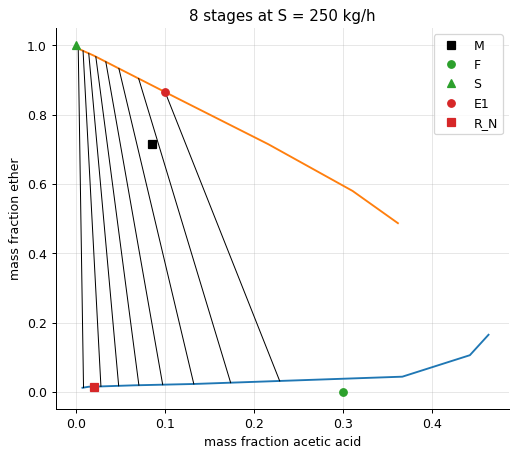

In [6]:
hn = ex.hunter_nash(tern, F, xF, 250.0, xS, xR_final=0.02)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.plot(d.xA_raffinate, d.xS_raffinate, "C0-"); ax.plot(d.yA_extract, d.yS_extract, "C1-")
for r, e in zip(hn["raffinates"], hn["extracts"]):
    ax.plot([r[0], e[0]], [r[1], e[1]], "k-", lw=0.8)
ax.plot(*hn["x_M"], "ks", label="M"); ax.plot(*xF, "C2o", label="F"); ax.plot(*xS, "C2^", label="S"); ax.plot(*hn["x_E1"], "C3o", label="E1"); ax.plot(*hn["x_RN"], "C3s", label="R_N")
ax.set(xlabel="mass fraction acetic acid", ylabel="mass fraction ether", title=f"{hn['stages']} stages at S = 250 kg/h"); ax.legend(); plt.show()

Each tie line drawn is a stage. The diagram shows why partially miscible systems need the full construction:
the extract carries water and the raffinate ether, the flows change from stage to stage, and no single
distribution coefficient describes the system - the library's Kremser functions are for the immiscible
limit, its `Ternary` and `hunter_nash` for the real thing.

## Inside the algorithm: the lever rule

In [7]:
M_, xM_ = ex.mixing_point(F, xF, 250.0, xS)
print("by hand: M =", M_, "at", np.round(xM_, 4), "; the mixing point lies at", round((250.0 / M_), 3), "of the way from F to S")

by hand: M = 350.0 at [0.0857 0.7143] ; the mixing point lies at 0.714 of the way from F to S


## Exercises
1. Recover 98 % of the acetic acid from the 30 % feed with an immiscible solvent of K = 3.0 (a better solvent than ether). Find S_min and the stages at 1.5 S_min, and compare with the ether case from the Hunter-Nash construction.
2. Cross-current extraction of the 30 % acid feed with ether: mix the feed with 100 kg/h of ether, separate, and repeat with fresh ether three times. Use the tie-line data (lever rule each time) and compare the final raffinate with the countercurrent result at the same total solvent.
3. **Implement it yourself:** write the Kremser form of countercurrent extraction from the stage balances (x_n = (x_{n-1} + E y_{n+1}/K)/(1+E)...) as an iterative stage-by-stage calculation and confirm the closed form for E = 1.5, N = 4.